Forma del vector de medias: (784, 1)
Forma de la matriz de covarianza: (784, 784)
Forma de la matriz de varianzas: (784, 784)


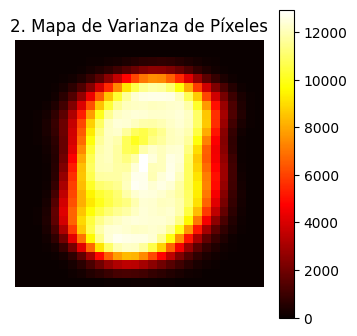

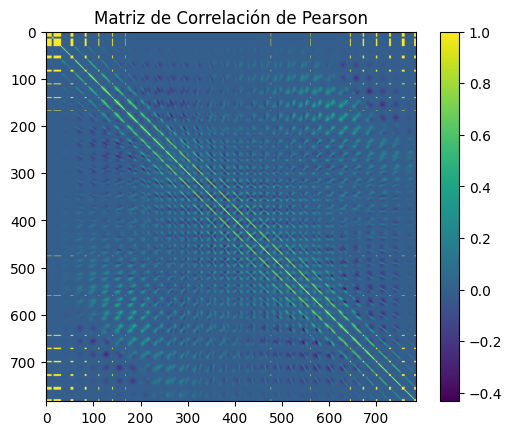

In [8]:
"""# 1. Esperanza Matemática (Media)

Dado un conjunto de imágenes donde cada imagen se representa como un vector, la media nos da la "imagen promedio".
Con 60000 imágenes de 28x28 píxeles (784 píxeles en total), calculamos la media matemática de cada píxel.
"""

import numpy as np
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Cargar los datos de MNIST (números escritos a mano)
(datos_imagenes, etiquetas_imagenes), _ = mnist.load_data()

# Redimensionar cada imagen de 28x28 a un vector plano de 784 elementos
datos_imagenes = datos_imagenes.reshape(-1, 28*28)
num_muestras = datos_imagenes.shape[0]

# Crear un vector de unos para realizar la suma matricial
vector_unos = np.ones((num_muestras, 1))

# Calcular el vector de medias (Esperanza Matemática)
vector_medias = (datos_imagenes.T @ vector_unos) / num_muestras
print("Forma del vector de medias:", vector_medias.shape)

"""# 2. Matriz de Covarianza y Varianza

Para ver cómo varían los píxeles entre sí, calculamos la matriz de covarianza.
Primero centramos los datos restándoles la media calculada anteriormente.
"""

# Pequeño valor (epsilon) para evitar divisiones por cero más adelante
epsilon = 1e-10

# Centrar los datos restando el vector de medias
datos_centrados = datos_imagenes - (vector_unos @ vector_medias.T) + epsilon

# Calcular la Matriz de Covarianza
matriz_covarianza = (1 / num_muestras) * (datos_centrados.T @ datos_centrados)
print("Forma de la matriz de covarianza:", matriz_covarianza.shape)

# Extraer la diagonal que representa la varianza de cada píxel individual
varianzas_individuales = np.diag(matriz_covarianza)

# Crear una matriz diagonal con las varianzas
matriz_varianzas = np.diag(varianzas_individuales)
print("Forma de la matriz de varianzas:", matriz_varianzas.shape)

# --- MEJORA 2: Visualizar la varianza como mapa de calor ---
plt.figure(figsize=(4, 4))
plt.imshow(varianzas_individuales.reshape(28, 28), cmap='hot')
plt.title("2. Mapa de Varianza de Píxeles")
plt.colorbar()
plt.axis('off')
plt.show()

r"""# 3. Coeficiente de Correlación de Pearson

El coeficiente de Pearson normaliza la covarianza para que sus valores estén entre -1 y 1.
Esto nos ayuda a visualizar mejor la relación directa o inversa entre los diferentes píxeles de las imágenes.
"""

# Preparar el denominador para la fórmula de correlación de Pearson
vector_varianzas_columna = np.diag(matriz_covarianza).reshape(-1, 1)
denominador_pearson = vector_varianzas_columna @ vector_varianzas_columna.T

# Calcular la matriz de correlación de Pearson
matriz_correlacion_pearson = matriz_covarianza / np.sqrt(denominador_pearson)

# Visualizar la matriz de correlación
plt.imshow(matriz_correlacion_pearson)
plt.colorbar()
plt.title("Matriz de Correlación de Pearson")
plt.show()
